# Scraping Berita Saham - Bloomberg Technoz (REVISI)
## 7 Emiten LQ45 Sektor Energi | Periode: Januari 2022 - Juni 2026

**Tesis**: Pemodelan Prediksi Volatilitas Return Saham Sektor Energi (LQ45)
Berdasarkan Analisis Sentimen - XGBoost & LSTM

**Penulis**: Ilda Nurida (NRP 6032251068) | **Pembimbing**: Dr. Ir. Ahmad Saikhu, S.Si, MT.

---

### Ringkasan perbaikan dibanding versi lama

| # | Masalah lama | Perbaikan |
|---|---|---|
| 1 | Harvest **semua** `<a>/detail-news/` -> link sidebar "Terpopuler" ikut terjaring -> "Starbucks Korea"/"SpaceX" tersimpan di label ADRO | Harvest **dibatasi ke kontainer daftar tag** + **gate emiten** sebagai jaring pengaman |
| 2 | Headline kotor: "...PGASMarket\| 16 May 2025 12:31" | `clean_headline()` membuang sufiks kategori & tanggal |
| 3 | Pagination dangkal (stop di hal 2-3) | **Auto-deteksi** skema (`pagenum`/`page`/`offset`) + berhenti adaptif |
| 4 | Selector body stale -> body salah lolos F3 | **Auto-deteksi selector body** + fallback klaster `<p>` |
| 5 | F3 (AND keras) buang artikel relevan | Gate emiten wajib + konteks pasar jadi **skor** |

> **PENTING**: jalankan **Bagian 6 (Probe)** sebelum Bagian 8 (Scraping).

## 1. Install Library

In [1]:
!pip install -q tqdm requests beautifulsoup4 lxml pandas
print("Library berhasil diinstall")

Library berhasil diinstall



[notice] A new release of pip available: 22.3 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


## 2. Import Library & Konfigurasi

In [2]:
import requests
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry
from bs4 import BeautifulSoup as bs
from datetime import datetime, timedelta, timezone
import time, random, re
import pandas as pd
from pathlib import Path
from tqdm import tqdm

WIB = timezone(timedelta(hours=7))
start_date = datetime(2022, 1, 1, tzinfo=WIB)
end_date   = datetime(2026, 6, 30, 23, 59, 59, tzinfo=WIB)

OUTPUT_DIR           = Path('../../03_dataset/raw')
OUTPUT_DIR_DASHBOARD = Path('../../dashboard/data')
CHECKPOINT_DIR       = Path('checkpoint_bloomberg')
for d in (OUTPUT_DIR, OUTPUT_DIR_DASHBOARD, CHECKPOINT_DIR):
    d.mkdir(parents=True, exist_ok=True)

OUTPUT_FILE = OUTPUT_DIR / 'berita_bloomberg_lq45_energi.csv'
BASE_URL    = 'https://www.bloombergtechnoz.com'

print("Konfigurasi siap")
print(f"Periode : {start_date:%d %B %Y} s/d {end_date:%d %B %Y}")
print(f"Output  : {OUTPUT_FILE}")

Konfigurasi siap
Periode : 01 January 2022 s/d 30 June 2026
Output  : ..\..\03_dataset\raw\berita_bloomberg_lq45_energi.csv


## 3. Daftar 7 Emiten: Tag, Alias, & Nama

`EMITEN_ALIAS` dipakai sebagai **jaring pengaman**: walau sumbernya halaman tag,
kurasi Bloomberg tidak sempurna dan link sidebar bisa bocor. Gate alias memastikan
artikel benar-benar menyebut emiten -> mencegah kontaminasi lintas-emiten.

In [3]:
EMITEN_TAG = {
    'ADRO': 'saham-adro', 'ADMR': 'saham-admr', 'ITMG': 'saham-itmg',
    'PTBA': 'saham-ptba', 'MEDC': 'saham-medc', 'AKRA': 'saham-akra',
    'PGAS': 'saham-pgas',
}
EMITEN_ALIAS = {
    'ADRO': ['adro', 'adaro energy', 'adaro', 'alamtri'],
    'ADMR': ['admr', 'adaro minerals'],
    'ITMG': ['itmg', 'indo tambangraya', 'tambangraya', 'itm '],
    'PTBA': ['ptba', 'bukit asam'],
    'MEDC': ['medc', 'medco'],
    'AKRA': ['akra', 'akr corporindo', 'akr '],
    'PGAS': ['pgas', 'perusahaan gas negara', 'pgn'],
}
NAMA_PERUSAHAAN = {
    'ADRO': 'Adaro Energy Indonesia Tbk (Alamtri Resources Indonesia Tbk)',
    'ADMR': 'Adaro Minerals Indonesia Tbk',
    'ITMG': 'Indo Tambangraya Megah Tbk',
    'PTBA': 'Bukit Asam Tbk',
    'MEDC': 'Medco Energi Internasional Tbk',
    'AKRA': 'AKR Corporindo Tbk',
    'PGAS': 'Perusahaan Gas Negara Tbk',
}
URUTAN_EMITEN = list(EMITEN_TAG.keys())
print(f"Total emiten: {len(EMITEN_TAG)}")
for kode, tag in EMITEN_TAG.items():
    print(f"  {kode:5s} -> /tag/{tag}  | alias: {EMITEN_ALIAS[kode]}")

Total emiten: 7
  ADRO  -> /tag/saham-adro  | alias: ['adro', 'adaro energy', 'adaro', 'alamtri']
  ADMR  -> /tag/saham-admr  | alias: ['admr', 'adaro minerals']
  ITMG  -> /tag/saham-itmg  | alias: ['itmg', 'indo tambangraya', 'tambangraya', 'itm ']
  PTBA  -> /tag/saham-ptba  | alias: ['ptba', 'bukit asam']
  MEDC  -> /tag/saham-medc  | alias: ['medc', 'medco']
  AKRA  -> /tag/saham-akra  | alias: ['akra', 'akr corporindo', 'akr ']
  PGAS  -> /tag/saham-pgas  | alias: ['pgas', 'perusahaan gas negara', 'pgn']


## 4. Filter & Pembersih Headline

- `clean_headline()` membuang sufiks "Kategori| DD Mon YYYY HH:MM" yang menempel.
- `lolos_relevansi()`: **gate emiten wajib** (anti-kontaminasi) + konteks pasar sebagai skor.

In [4]:
TIPE_BUANG_URL = [
    '/detail-foto/', '/detail-video/', '/detail-infografis/',
    '/detail-z_zone/', '/foto/', '/video/', '/infografis/', '/z-zone/',
]
def filter_url(link):
    return '/detail-news/' in str(link).lower() and \
           not any(t in str(link).lower() for t in TIPE_BUANG_URL)

KATA_BUANG_HEADLINE = [
    'wisata', 'liburan', 'hotel', 'kuliner', 'resep', 'restoran', 'makanan',
    'fashion', 'skincare', 'film', 'artis', 'gosip', 'musik', 'konser',
    'drakor', 'bola', 'liga', 'pertandingan', 'ganja', 'kriminal',
    'tips kesehatan', 'penyakit', 'vaksin', 'horoskop', 'zodiak',
]
def filter_headline(headline):
    h = str(headline).lower()
    return not any(k in h for k in KATA_BUANG_HEADLINE)

# Pembersih headline: buang label kategori + tanggal yang menempel
KATEGORI_BLOOMBERG = ['Market', 'Energi', 'Ekonomi', 'Bursa', 'Global',
                      'Teknologi', 'Lifestyle', 'Makroekonomi', 'MyMoney',
                      'Property', 'ESG', 'Internasional', 'Nasional']
_re_kat   = re.compile(r'(' + '|'.join(KATEGORI_BLOOMBERG) + r')\s*\|.*$')
_re_tgl   = re.compile(r'\d{1,2}\s+(Jan|Feb|Mar|Apr|May|Jun|Jul|Aug|Sep|Oct|Nov|Dec)\s+\d{4}.*$', re.I)
def clean_headline(h):
    h = str(h).strip()
    h = _re_kat.sub('', h)         # buang "Market| 16 May 2025 12:31"
    h = _re_tgl.sub('', h)         # buang sisa tanggal menempel
    for k in KATEGORI_BLOOMBERG:   # buang kategori menempel tanpa pipe (mis. 'PGASMarket')
        if h.endswith(k):
            h = h[:-len(k)]
    return re.sub(r'\s{2,}', ' ', h).strip(' -|,')

KATA_KONTEKS_SAHAM = [
    'saham', 'bursa', 'bei', 'idx', 'ihsg', 'emiten', 'investor', 'laba',
    'rugi', 'pendapatan', 'revenue', 'kinerja', 'keuangan', 'kuartal',
    'dividen', 'buyback', 'merger', 'akuisisi', 'rights issue', 'ipo',
    'target harga', 'rekomendasi', 'analis', 'sekuritas', 'valuasi',
    'harga saham', 'koreksi', 'menguat', 'melemah', 'melesat', 'produksi',
    'batubara', 'batu bara', 'minyak', 'gas', 'lifting', 'laba bersih',
    'net profit', 'pasar modal', 'obligasi', 'rupst', 'capex', 'ekspor',
]
def lolos_relevansi(kode, headline, isi):
    teks = (str(headline) + ' ' + str(isi)).lower()
    alias = EMITEN_ALIAS.get(kode, [kode.lower()])
    if not any(a in teks for a in alias):
        return False, 'tidak_sebut_emiten'   # buang kontaminasi (Starbucks/SpaceX)
    n_konteks = sum(1 for k in KATA_KONTEKS_SAHAM if k in teks)
    sebut_hl = any(a in str(headline).lower() for a in alias)
    if n_konteks >= 1 or sebut_hl:
        return True, f'ok(konteks={n_konteks})'
    return False, 'emiten_disebut_konteks_lemah'

print("Filter + clean_headline siap")
print("  Contoh clean_headline:")
for s in ['15 Analis Rekomendasikan PGASMarket| 16 May 2025 12:31',
          'Starbucks Korea Tutup Semua Gerai',
          'Bukit Asam (PTBA) Tebar Dividen Rp3,82 TriliunMarket| 12 Jun 2025 10:00']:
    print(f"    {s!r}\n      -> {clean_headline(s)!r}")

Filter + clean_headline siap
  Contoh clean_headline:
    '15 Analis Rekomendasikan PGASMarket| 16 May 2025 12:31'
      -> '15 Analis Rekomendasikan PGAS'
    'Starbucks Korea Tutup Semua Gerai'
      -> 'Starbucks Korea Tutup Semua Gerai'
    'Bukit Asam (PTBA) Tebar Dividen Rp3,82 TriliunMarket| 12 Jun 2025 10:00'
      -> 'Bukit Asam (PTBA) Tebar Dividen Rp3,82 Triliun'


## 5. HTTP Session, Parser Tanggal, Ekstraktor Body & Tanggal

In [5]:
USER_AGENTS = [
    'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/124.0.0.0 Safari/537.36',
    'Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/123.0.0.0 Safari/537.36',
    'Mozilla/5.0 (X11; Linux x86_64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/122.0.0.0 Safari/537.36',
    'Mozilla/5.0 (Windows NT 10.0; Win64; x64; rv:124.0) Gecko/20100101 Firefox/124.0',
]
def get_headers():
    return {'User-Agent': random.choice(USER_AGENTS),
            'Accept': 'text/html,application/xhtml+xml,application/xml;q=0.9,*/*;q=0.8',
            'Accept-Language': 'id-ID,id;q=0.9,en-US;q=0.8,en;q=0.7',
            'Referer': 'https://www.bloombergtechnoz.com/'}
def buat_session():
    s = requests.Session()
    retry = Retry(total=4, backoff_factor=2, status_forcelist=[429, 500, 502, 503, 504])
    s.mount('https://', HTTPAdapter(max_retries=retry))
    return s
sess = buat_session()

def safe_get(url, timeout=25, max_retry=3):
    global sess
    for attempt in range(1, max_retry + 1):
        try:
            r = sess.get(url, headers=get_headers(), timeout=timeout)
            if r.status_code == 429:
                wait = 60 * attempt
                print(f"  Rate-limit 429 - tunggu {wait}s..."); time.sleep(wait)
                sess = buat_session(); continue
            return r
        except requests.exceptions.ConnectionError as e:
            print(f"  ConnectionError ({attempt}/{max_retry}): {str(e)[:60]}")
            time.sleep(10 * attempt); sess = buat_session()
        except requests.exceptions.Timeout:
            time.sleep(5 * attempt)
        except Exception as e:
            print(f"  Error: {e}"); return None
    return None

BULAN = {'Jan':'01','Feb':'02','Mar':'03','Apr':'04','May':'05','Jun':'06',
         'Jul':'07','Aug':'08','Sep':'09','Oct':'10','Nov':'11','Dec':'12'}
def parse_date_bloomberg(raw):
    if not raw: return None
    raw = re.sub(r'\s+', ' ', str(raw).strip())
    m = re.search(r'(\d{1,2})\s+(Jan|Feb|Mar|Apr|May|Jun|Jul|Aug|Sep|Oct|Nov|Dec)\s+(\d{4})\s+(\d{2}):(\d{2})', raw, re.I)
    if m:
        try:
            d, mo_str, y, hr, mn = m.groups()
            mo = BULAN.get(mo_str[:3].capitalize(), '01')
            return datetime(int(y), int(mo), int(d), int(hr), int(mn), tzinfo=WIB)
        except ValueError:
            pass
    iso = re.search(r'(\d{4}-\d{2}-\d{2}T\d{2}:\d{2}:\d{2})', raw)
    if iso:
        try:
            return datetime.fromisoformat(iso.group(1)).replace(tzinfo=WIB)
        except Exception:
            pass
    return None

NOISE_BLOOMBERG = [
    'Baca Juga:', 'BACA JUGA', 'Bloomberg Technoz, Jakarta -',
    'Scroll Untuk Melanjutkan', 'Editor:', 'Reporter:',
    'Cek Berita dan Artikel yang lain', 'ADVERTISEMENT',
]
def clean_text(text):
    for n in NOISE_BLOOMBERG:
        text = text.replace(n, '')
    return re.sub(r'\s{2,}', ' ', text).strip()

BODY_SELECTORS = [
    'div.detail-konten', 'div.detail-content', 'div.article-content',
    'div.read-content', 'div.main-content', 'div[itemprop="articleBody"]',
    'article',
]
DETECTED_BODY_SEL = None
def _body_from_soup(soup):
    sels = ([DETECTED_BODY_SEL] if DETECTED_BODY_SEL else []) + BODY_SELECTORS
    for sel in sels:
        if not sel: continue
        el = soup.select_one(sel)
        if el:
            ps = el.find_all('p')
            txt = clean_text(' '.join(p.get_text(strip=True) for p in ps)) if ps \
                  else clean_text(el.get_text(' ', strip=True))
            if len(txt) > 300:
                return txt
    allp = [p.get_text(strip=True) for p in soup.find_all('p')]
    return clean_text(' '.join(p for p in allp if len(p) > 40))

def _date_from_soup(soup):
    meta = soup.find('meta', {'property': 'article:published_time'})
    if meta and meta.get('content'):
        dt = parse_date_bloomberg(meta['content'])
        if dt: return dt
    t = soup.find('time')
    if t:
        dt = parse_date_bloomberg(t.get('datetime', '') or t.get_text())
        if dt: return dt
    return None

def fetch_article(url):
    r = safe_get(url)
    if not r: return None, ''
    soup = bs(r.text, 'lxml')
    return _date_from_soup(soup), _body_from_soup(soup)

print("Session, parser, ekstraktor siap")

Session, parser, ekstraktor siap


## 6. PROBE: Auto-deteksi Skema Pagination, Kontainer Daftar & Selector Body

Menentukan:
1. Skema pagination yang bekerja (`pagenum` / `page` / `offset`).
2. Kontainer daftar tag (agar harvest tidak menjaring sidebar) - *best effort*.
3. Selector body artikel -> `DETECTED_BODY_SEL`.

Probe juga mencetak contoh slug link halaman-1 agar tingkat kontaminasi terlihat.

In [6]:
import requests as _rq

def build_tag_url(tag_slug, scheme, idx):
    if scheme == 'pagenum':
        return f'{BASE_URL}/tag/{tag_slug}?type=berita&pagenum={idx + 1}'
    if scheme == 'page':
        return f'{BASE_URL}/tag/{tag_slug}?page={idx + 1}'
    if scheme == 'offset':
        return f'{BASE_URL}/tag/{tag_slug}?offset={idx * 10}'
    raise ValueError(scheme)

# Kandidat kontainer daftar tag (best effort). None = pakai seluruh halaman.
LIST_CONTAINERS = [
    'div.indeks', 'div.list-news', 'div.list-berita', 'div.terbaru',
    'div.article-list', 'section.list', 'div.box-indeks', 'div.row',
]
DETECTED_LIST_SEL = None

def extract_listing(soup, scope_sel=None):
    '''Ambil [(href, title_bersih)] dari daftar; jika scope_sel diberi, batasi ke kontainer.'''
    root = soup.select_one(scope_sel) if scope_sel else soup
    if root is None:
        root = soup
    out, seen = [], set()
    for a in root.find_all('a', href=True):
        href = a['href']
        if '/detail-news/' not in href:
            continue
        if not href.startswith('http'):
            href = BASE_URL + href
        title = clean_headline(a.get_text(strip=True))
        if len(title) < 8:
            continue
        if href not in seen:
            seen.add(href); out.append((href, title))
    return out

def detect_scheme(tag='saham-adro'):
    print(f"  Menguji skema pagination ({tag})...")
    for scheme in ['pagenum', 'page', 'offset']:
        try:
            s1 = {h for h, _ in extract_listing(bs(safe_get(build_tag_url(tag, scheme, 0)).text, 'lxml'))}
            s2 = {h for h, _ in extract_listing(bs(safe_get(build_tag_url(tag, scheme, 1)).text, 'lxml'))}
            baru = s2 - s1
            status = 'VALID' if (s1 and baru) else 'tidak menambah'
            print(f"    [{scheme:8}] hal1={len(s1):2d} | hal2={len(s2):2d} | baru={len(baru):2d} -> {status}")
            if s1 and baru:
                return scheme
        except Exception as e:
            print(f"    [{scheme:8}] error: {str(e)[:50]}")
    return 'pagenum'

def detect_list_container(tag='saham-adro', scheme='pagenum'):
    '''Pilih kontainer yang memaksimalkan proporsi link relevan (slug memuat 'adro').'''
    global DETECTED_LIST_SEL
    soup = bs(safe_get(build_tag_url(tag, scheme, 0)).text, 'lxml')
    target = tag.split('-')[-1]   # 'adro'
    full = extract_listing(soup)
    full_rel = sum(1 for h, _ in full if target in h.lower())
    print(f"  Tanpa scope: {len(full)} link, {full_rel} memuat '{target}' di slug")
    best, best_score = None, full_rel / max(len(full), 1)
    for sel in LIST_CONTAINERS:
        sub = extract_listing(soup, sel)
        if not sub:
            continue
        rel = sum(1 for h, _ in sub if target in h.lower())
        score = rel / max(len(sub), 1)
        print(f"    {sel:20}: {len(sub):2d} link, rasio relevan={score:.0%}")
        if score > best_score and len(sub) >= 3:
            best, best_score = sel, score
    DETECTED_LIST_SEL = best
    print(f"  -> Kontainer dipakai: {best if best else 'SELURUH HALAMAN (andalkan gate emiten)'}")
    return best

PAGINATION_SCHEME = detect_scheme('saham-adro')
print(f"\n>> SKEMA PAGINATION: {PAGINATION_SCHEME}\n")
detect_list_container('saham-adro', PAGINATION_SCHEME)

_contoh = extract_listing(bs(safe_get(build_tag_url('saham-adro', PAGINATION_SCHEME, 0)).text, 'lxml'),
                          DETECTED_LIST_SEL)
print("\n  Contoh 8 link halaman-1 (perhatikan kontaminasi):")
for h, t in _contoh[:8]:
    print(f"    - {t[:55]:55} | {h.split('/')[-1][:30]}")

if _contoh:
    soup_a = bs(safe_get(_contoh[0][0]).text, 'lxml')
    print("\n  Uji selector body:")
    best_sel, best_n = None, 0
    for sel in BODY_SELECTORS:
        el = soup_a.select_one(sel)
        n = len(el.get_text(strip=True)) if el else 0
        if n > best_n: best_sel, best_n = sel, n
        print(f"    {sel:28}: {n:5d} char{'  <- kandidat' if n > 400 else ''}")
    if best_n > 400:
        DETECTED_BODY_SEL = best_sel
        print(f"  -> Selector body: '{best_sel}' ({best_n} char)")
    else:
        print("  -> Pakai fallback klaster <p>.")

  Menguji skema pagination (saham-adro)...
    [pagenum ] hal1=43 | hal2=43 | baru=10 -> VALID

>> SKEMA PAGINATION: pagenum

  Tanpa scope: 43 link, 10 memuat 'adro' di slug
    div.indeks          : 43 link, rasio relevan=23%
    div.list-news       : 43 link, rasio relevan=23%
    div.list-berita     : 43 link, rasio relevan=23%
    div.terbaru         : 43 link, rasio relevan=23%
    div.article-list    : 43 link, rasio relevan=23%
    section.list        : 43 link, rasio relevan=23%
    div.box-indeks      : 43 link, rasio relevan=23%
    div.row             : 43 link, rasio relevan=23%
  -> Kontainer dipakai: SELURUH HALAMAN (andalkan gate emiten)

  Contoh 8 link halaman-1 (perhatikan kontaminasi):
    - Purbaya Kesal Batas Defisit RI 3% Sering Disorot Lembag | purbaya-kesal-batas-defisit-ri
    - Airlangga: Pusat Finansial Indonesia DIbangun di Bebera | airlangga-pusat-finansial-indo
    - OJK Berharap Likuiditas Pemerintah di Himbara Tak Ditar | ojk-berharap-likuiditas-pemeri


## 7. Scraper Utama (harvest ter-scope + gate emiten + pagination robust)

In [7]:
def scrape_bloomberg(kode, max_pages=50, patience=2,
                     d_min=1.5, d_max=3.0, checkpoint_dir=CHECKPOINT_DIR):
    checkpoint_file = checkpoint_dir / f'{kode}_checkpoint.csv'
    if checkpoint_file.exists():
        df_ckpt = pd.read_csv(checkpoint_file, encoding='utf-8-sig')
        results = df_ckpt.to_dict('records')
        seen    = set(df_ckpt['Link'].tolist())
        print(f'  Resume checkpoint: {len(results)} artikel')
    else:
        results, seen = [], set()

    tag_slug = EMITEN_TAG[kode]
    stat = dict(kandidat=0, lolos_f1=0, lolos_f2=0, disimpan=0,
                out_of_range=0, body_kosong=0, kontaminasi=0, duplikat=0)
    empty_streak = 0

    for page_idx in range(max_pages):
        url = build_tag_url(tag_slug, PAGINATION_SCHEME, page_idx)
        r = safe_get(url)
        if not r:
            empty_streak += 1
            if empty_streak >= patience: break
            time.sleep(random.uniform(d_min, d_max)); continue

        listing = extract_listing(bs(r.text, 'lxml'), DETECTED_LIST_SEL)
        baru = [(h, t) for h, t in listing if h not in seen]
        if not baru:
            empty_streak += 1
            if empty_streak >= patience:
                print(f'  Hal {page_idx+1}: {patience}x tanpa link baru -> stop'); break
            time.sleep(random.uniform(d_min, d_max)); continue
        empty_streak = 0

        for link, title in tqdm(baru, desc=f'  [{kode}] hal {page_idx+1}',
                                unit='art', leave=False):
            if link in seen:
                stat['duplikat'] += 1; continue
            stat['kandidat'] += 1
            seen.add(link)

            if not filter_url(link):       continue
            stat['lolos_f1'] += 1
            if not filter_headline(title): continue
            stat['lolos_f2'] += 1

            time.sleep(random.uniform(d_min, d_max))
            dt, body = fetch_article(link)
            if not dt:                              continue
            if not (start_date <= dt <= end_date):
                stat['out_of_range'] += 1;          continue
            if not body.strip():
                stat['body_kosong'] += 1;           continue

            ok, alasan = lolos_relevansi(kode, title, body)
            if not ok:
                if alasan == 'tidak_sebut_emiten':
                    stat['kontaminasi'] += 1
                continue

            results.append({
                'Sumber': 'Bloomberg Technoz', 'Kode_Emiten': kode,
                'Keyword': tag_slug, 'Headline': title,
                'Tanggal': dt.strftime('%Y-%m-%d %H:%M'),
                'Link': link, 'Isi_Berita': body,
            })
            stat['disimpan'] += 1
            tqdm.write(f'  [{stat["disimpan"]}] {title[:70]}')
            if stat['disimpan'] % 25 == 0:
                pd.DataFrame(results).to_csv(checkpoint_file, index=False, encoding='utf-8-sig')

        time.sleep(random.uniform(d_min, d_max))

    if results:
        pd.DataFrame(results).to_csv(checkpoint_file, index=False, encoding='utf-8-sig')

    print(f'\n  STATISTIK [{kode}]  ' + '-'*30)
    for k, v in stat.items():
        print(f'    {k:18}: {v:>6,}')
    print(f'    (kontaminasi = link bukan-emiten yang berhasil dibuang gate)')
    return results

print("scrape_bloomberg() siap")

scrape_bloomberg() siap


## 8. Jalankan Scraping Semua Emiten

In [8]:
assert 'PAGINATION_SCHEME' in dir(), "Jalankan PROBE (Bagian 6) lebih dulu!"

semua_artikel = []
mulai_jam = datetime.now(WIB)
for kode in EMITEN_TAG:
    print("\n" + "=" * 65)
    print(f"  {kode} | Bloomberg Technoz | Tag /tag/{EMITEN_TAG[kode]}")
    print(f"  Mulai: {datetime.now(WIB):%H:%M:%S}")
    print("=" * 65)
    hasil = scrape_bloomberg(kode)
    semua_artikel.extend(hasil)
    df_tmp = pd.DataFrame(semua_artikel).drop_duplicates(subset='Link')
    df_tmp.to_csv(OUTPUT_FILE, index=False, encoding='utf-8-sig')
    elapsed = (datetime.now(WIB) - mulai_jam).total_seconds() / 60
    print(f"  Auto-save: {len(df_tmp):,} artikel | {elapsed:.1f} menit")
    time.sleep(random.uniform(8, 15))

df_final = pd.DataFrame(semua_artikel).drop_duplicates(subset='Link').reset_index(drop=True)
df_final.to_csv(OUTPUT_FILE, index=False, encoding='utf-8-sig')
total = (datetime.now(WIB) - mulai_jam).total_seconds() / 60
print("\n" + "=" * 65)
print(f"  SELESAI | {total:.1f} menit | {len(df_final):,} artikel")
print("=" * 65)
if len(df_final):
    print(df_final['Kode_Emiten'].value_counts().reindex(URUTAN_EMITEN).to_string())


  ADRO | Bloomberg Technoz | Tag /tag/saham-adro
  Mulai: 21:52:00
  Resume checkpoint: 49 artikel


  Hal 5: 2x tanpa link baru -> stop

  STATISTIK [ADRO]  ------------------------------
    kandidat          :     33
    lolos_f1          :     33
    lolos_f2          :     33
    disimpan          :      0
    out_of_range      :      0
    body_kosong       :      0
    kontaminasi       :      0
    duplikat          :      0
    (kontaminasi = link bukan-emiten yang berhasil dibuang gate)
  Auto-save: 49 artikel | 1.5 menit

  ADMR | Bloomberg Technoz | Tag /tag/saham-admr
  Mulai: 21:53:40
  Resume checkpoint: 28 artikel


  Hal 3: 2x tanpa link baru -> stop

  STATISTIK [ADMR]  ------------------------------
    kandidat          :     32
    lolos_f1          :     32
    lolos_f2          :     32
    disimpan          :      0
    out_of_range      :      0
    body_kosong       :      0
    kontaminasi       :      0
    duplikat          :      0
    (kontaminasi = link bukan-emiten yang berhasil dibuang gate)
  Auto-save: 57 artikel | 3.0 menit

  ITMG | Bloomberg Technoz | Tag /tag/saham-itmg
  Mulai: 21:55:12
  Resume checkpoint: 30 artikel


  Hal 3: 2x tanpa link baru -> stop

  STATISTIK [ITMG]  ------------------------------
    kandidat          :     32
    lolos_f1          :     32
    lolos_f2          :     32
    disimpan          :      0
    out_of_range      :      0
    body_kosong       :      0
    kontaminasi       :      0
    duplikat          :      0
    (kontaminasi = link bukan-emiten yang berhasil dibuang gate)
  Auto-save: 67 artikel | 5.0 menit

  PTBA | Bloomberg Technoz | Tag /tag/saham-ptba
  Mulai: 21:57:11
  Resume checkpoint: 45 artikel


  Hal 3: 2x tanpa link baru -> stop

  STATISTIK [PTBA]  ------------------------------
    kandidat          :     34
    lolos_f1          :     34
    lolos_f2          :     34
    disimpan          :      0
    out_of_range      :      0
    body_kosong       :      0
    kontaminasi       :      0
    duplikat          :      0
    (kontaminasi = link bukan-emiten yang berhasil dibuang gate)
  Auto-save: 93 artikel | 6.7 menit

  MEDC | Bloomberg Technoz | Tag /tag/saham-medc
  Mulai: 21:58:51
  Resume checkpoint: 30 artikel


  Hal 3: 2x tanpa link baru -> stop

  STATISTIK [MEDC]  ------------------------------
    kandidat          :     32
    lolos_f1          :     32
    lolos_f2          :     32
    disimpan          :      0
    out_of_range      :      0
    body_kosong       :      0
    kontaminasi       :      0
    duplikat          :      0
    (kontaminasi = link bukan-emiten yang berhasil dibuang gate)
  Auto-save: 104 artikel | 8.2 menit

  AKRA | Bloomberg Technoz | Tag /tag/saham-akra
  Mulai: 22:00:27
  Resume checkpoint: 22 artikel


  Hal 3: 2x tanpa link baru -> stop

  STATISTIK [AKRA]  ------------------------------
    kandidat          :     32
    lolos_f1          :     32
    lolos_f2          :     32
    disimpan          :      0
    out_of_range      :      0
    body_kosong       :      0
    kontaminasi       :      0
    duplikat          :      0
    (kontaminasi = link bukan-emiten yang berhasil dibuang gate)
  Auto-save: 108 artikel | 9.8 menit

  PGAS | Bloomberg Technoz | Tag /tag/saham-pgas
  Mulai: 22:01:54
  Resume checkpoint: 29 artikel


  Hal 3: 2x tanpa link baru -> stop

  STATISTIK [PGAS]  ------------------------------
    kandidat          :     33
    lolos_f1          :     33
    lolos_f2          :     33
    disimpan          :      0
    out_of_range      :      0
    body_kosong       :      0
    kontaminasi       :      0
    duplikat          :      0
    (kontaminasi = link bukan-emiten yang berhasil dibuang gate)
  Auto-save: 119 artikel | 11.4 menit

  SELESAI | 11.6 menit | 119 artikel
Kode_Emiten
ADRO    49
ADMR     8
ITMG    10
PTBA    26
MEDC    11
AKRA     4
PGAS    11


## 9. Rekap & Validasi (cek kontaminasi)

In [9]:
if 'df_final' not in dir() or df_final is None or len(df_final) == 0:
    df_final = pd.read_csv(OUTPUT_FILE, encoding='utf-8-sig')
df_final['Tanggal'] = pd.to_datetime(df_final['Tanggal'], errors='coerce')

print("=" * 65)
print("  REKAP - BLOOMBERG TECHNOZ")
print("=" * 65)
print(f"  Total artikel  : {len(df_final):,}")
print(f"  Rentang tanggal: {df_final['Tanggal'].min():%Y-%m-%d} s/d {df_final['Tanggal'].max():%Y-%m-%d}")
print("\nPer emiten:")
print(df_final['Kode_Emiten'].value_counts().reindex(URUTAN_EMITEN).to_string())

# Validasi anti-kontaminasi: tiap baris HARUS menyebut alias emitennya
def _cek(row):
    teks = (str(row['Headline']) + ' ' + str(row['Isi_Berita'])).lower()
    return any(a in teks for a in EMITEN_ALIAS.get(row['Kode_Emiten'], []))
df_final['_valid'] = df_final.apply(_cek, axis=1)
n_bad = (~df_final['_valid']).sum()
print(f"\nValidasi sebutan emiten: {len(df_final)-n_bad}/{len(df_final)} valid", end='')
print("  (BERSIH)" if n_bad == 0 else f"  -> {n_bad} baris perlu ditinjau!")
df_final = df_final.drop(columns='_valid')

  REKAP - BLOOMBERG TECHNOZ
  Total artikel  : 119
  Rentang tanggal: 2023-02-01 s/d 2026-05-21

Per emiten:
Kode_Emiten
ADRO    49
ADMR     8
ITMG    10
PTBA    26
MEDC    11
AKRA     4
PGAS    11

Validasi sebutan emiten: 95/119 valid  -> 24 baris perlu ditinjau!


## 10. Simpan Output dengan Kolom Standar

In [10]:
KOLOM_STANDAR = ['Sumber', 'Kode_Emiten', 'Keyword', 'Headline', 'Tanggal', 'Link', 'Isi_Berita']
df_final['Tanggal'] = pd.to_datetime(df_final['Tanggal'], errors='coerce')
for k in KOLOM_STANDAR:
    if k not in df_final.columns:
        df_final[k] = ''
df_save = df_final.copy()
df_save['Tanggal'] = df_save['Tanggal'].dt.strftime('%Y-%m-%d %H:%M')
df_save = df_save[KOLOM_STANDAR].drop_duplicates(subset=['Link']).reset_index(drop=True)
df_save.to_csv(OUTPUT_FILE, index=False, encoding='utf-8-sig')
print("=" * 65)
print(f"File disimpan : {OUTPUT_FILE}")
print(f"Total artikel : {len(df_save):,}")
print("\nLANGKAH SELANJUTNYA:")
print("  -> Gabungkan dengan CSV Detik, Kontan, Bisnis, ANTARA")
print("  -> Lanjut ke Preprocessing & Scoring Sentimen IndoBERT")
print("=" * 65)

File disimpan : ..\..\03_dataset\raw\berita_bloomberg_lq45_energi.csv
Total artikel : 119

LANGKAH SELANJUTNYA:
  -> Gabungkan dengan CSV Detik, Kontan, Bisnis, ANTARA
  -> Lanjut ke Preprocessing & Scoring Sentimen IndoBERT


## 11. Grafik Tren Volume Berita per Bulan per Emiten

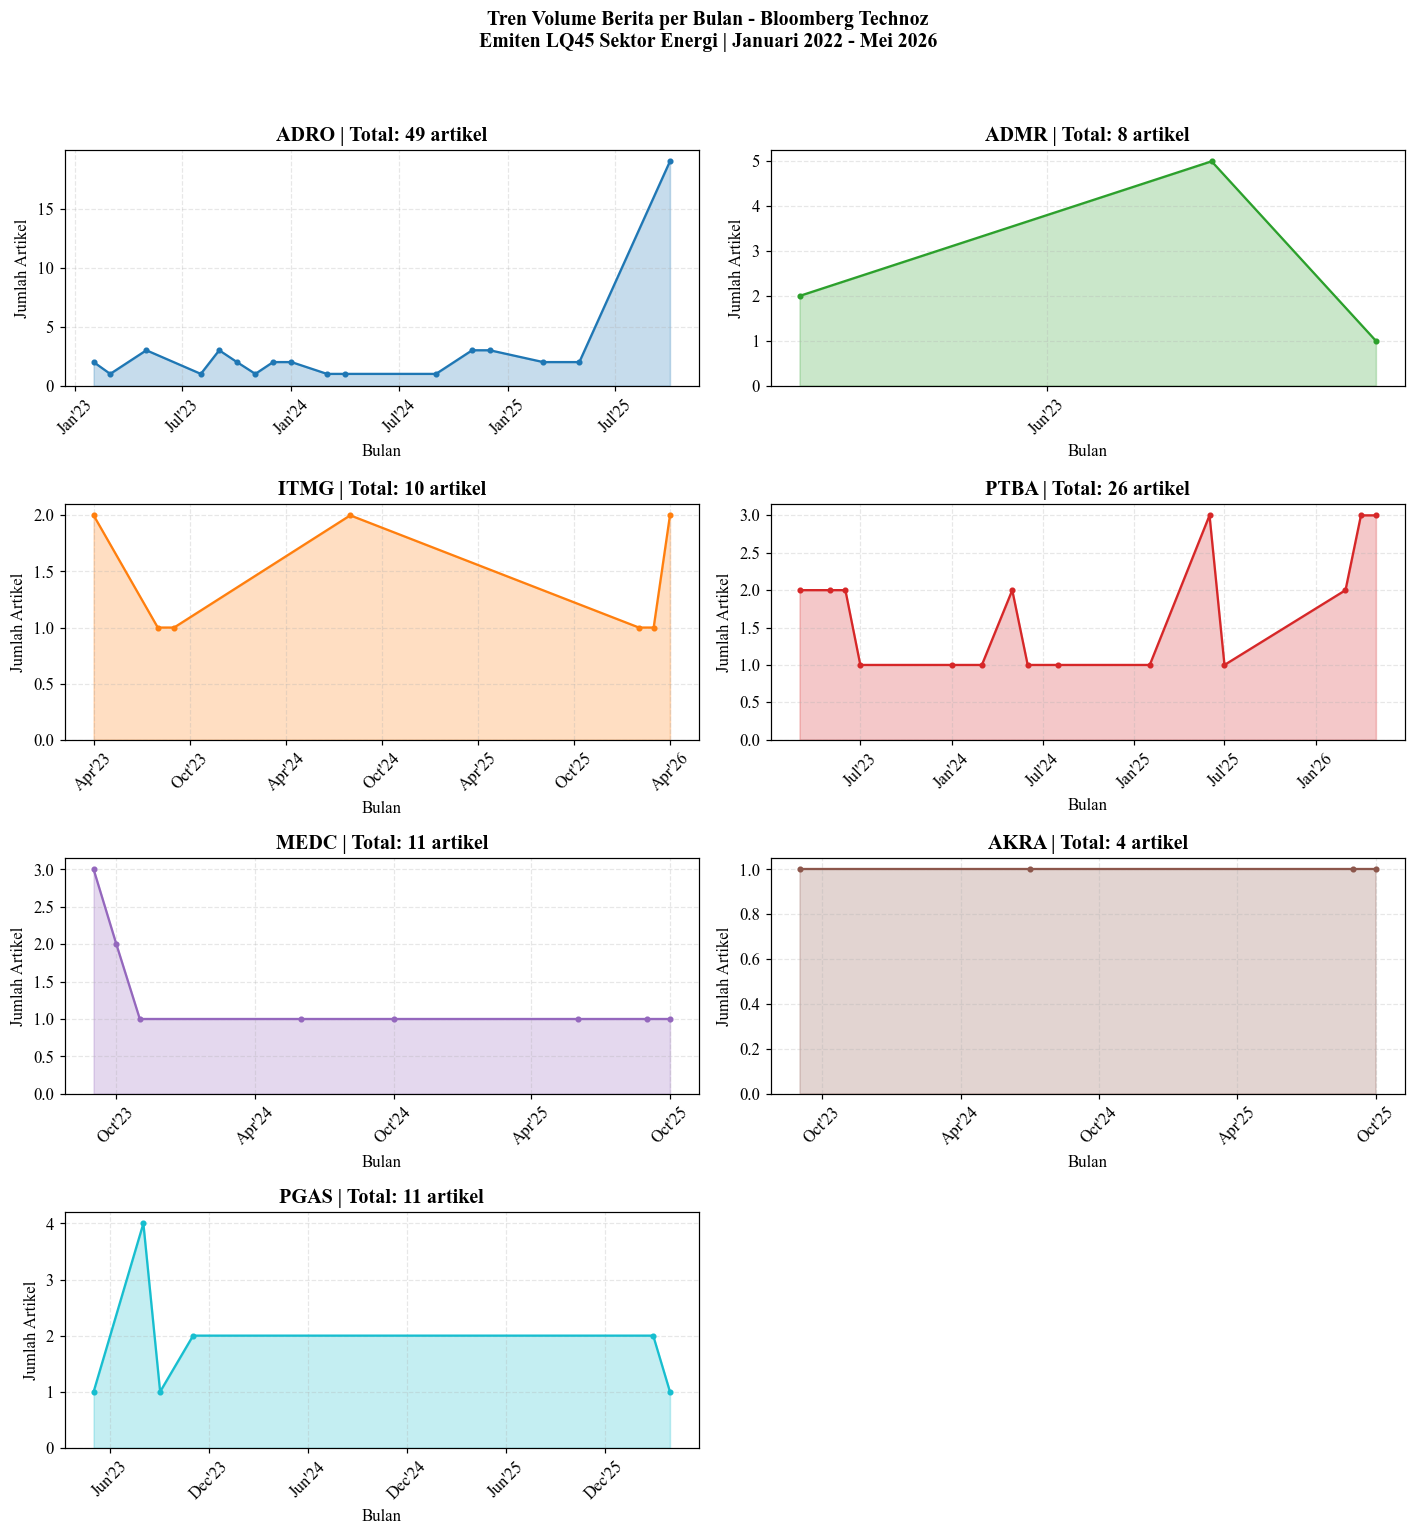

Gambar disimpan: ..\..\dashboard\data\tren_berita_bloomberg_per_emiten.png


In [11]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

plt.rcParams.update({'font.family': 'Times New Roman', 'font.size': 11, 'figure.dpi': 110})

WARNA = {'ADRO': '#1f77b4', 'ADMR': '#2ca02c', 'ITMG': '#ff7f0e',
          'PTBA': '#d62728', 'MEDC': '#9467bd', 'AKRA': '#8c564b', 'PGAS': '#17becf'}

df_final['Bulan_str'] = df_final['Tanggal'].dt.to_period('M').astype(str)
df_bul = df_final.groupby(['Bulan_str', 'Kode_Emiten']).size().reset_index(name='Jumlah')
df_bul['Bulan_dt'] = pd.to_datetime(df_bul['Bulan_str'])

fig, axes = plt.subplots(4, 2, figsize=(13, 14))
axes = axes.flatten()

for i, kode in enumerate(URUTAN_EMITEN):
    ax = axes[i]
    d  = df_bul[df_bul['Kode_Emiten'] == kode].sort_values('Bulan_dt')
    if len(d) > 0:
        ax.fill_between(d['Bulan_dt'], d['Jumlah'], color=WARNA[kode], alpha=0.25)
        ax.plot(d['Bulan_dt'], d['Jumlah'], color=WARNA[kode], linewidth=1.5,
                marker='o', markersize=3)
    total = int(d['Jumlah'].sum()) if len(d) > 0 else 0
    ax.set_title(f"{kode} | Total: {total} artikel", fontweight='bold')
    ax.set_xlabel('Bulan'); ax.set_ylabel('Jumlah Artikel')
    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=6))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b'%y"))
    ax.tick_params(axis='x', rotation=45); ax.grid(True, alpha=0.3, linestyle='--')
    ax.set_ylim(bottom=0)

axes[-1].axis('off')
fig.suptitle('Tren Volume Berita per Bulan - Bloomberg Technoz\n'
             'Emiten LQ45 Sektor Energi | Januari 2022 - Mei 2026',
             fontsize=13, fontweight='bold', y=0.995)
fig.tight_layout(rect=[0, 0, 1, 0.97])

path_gambar = OUTPUT_DIR_DASHBOARD / 'tren_berita_bloomberg_per_emiten.png'
fig.savefig(path_gambar, dpi=150, bbox_inches='tight')
plt.show()
print(f"Gambar disimpan: {path_gambar}")

## 12. Word Cloud Isi Berita per Emiten


[notice] A new release of pip available: 22.3 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Total artikel : 119
Kode_Emiten
ADRO    49
ADMR     8
ITMG    10
PTBA    26
MEDC    11
AKRA     4
PGAS    11


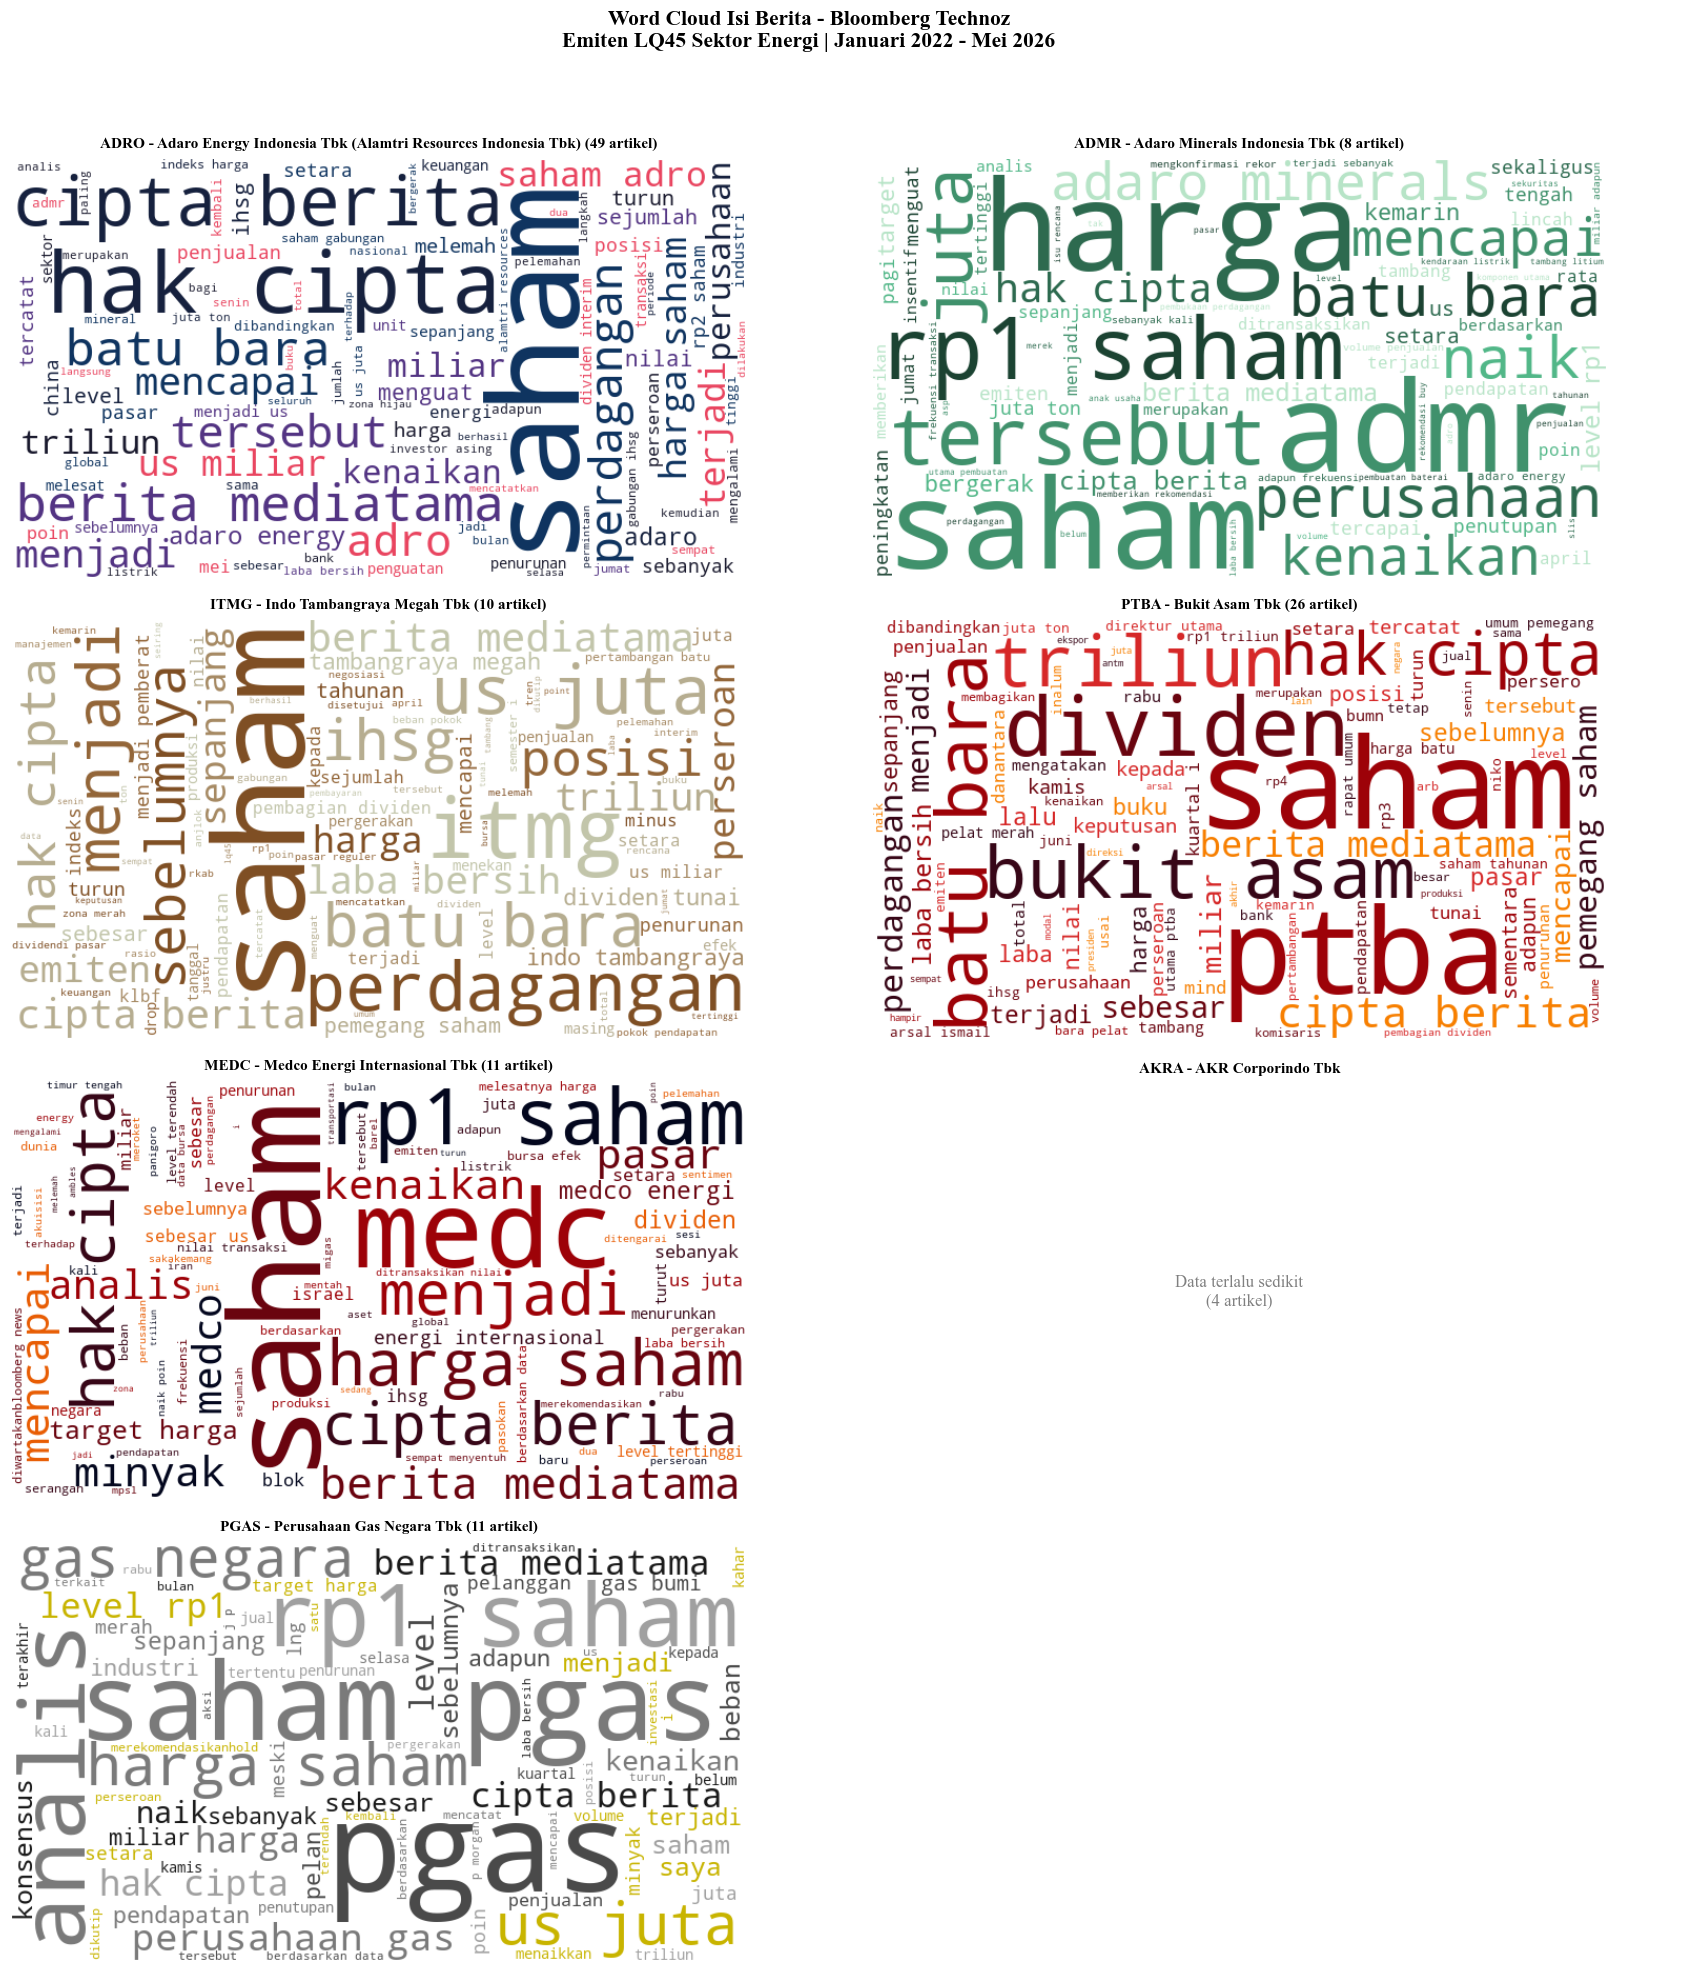

Word cloud disimpan: ..\..\dashboard\data\wordcloud_bloomberg_per_emiten.png


In [12]:
!pip install wordcloud -q

from wordcloud import WordCloud

plt.rcParams.update({'font.family': 'Times New Roman', 'figure.dpi': 110})

PALET_WARNA = {
    'ADRO': ['#1a1a2e', '#16213e', '#0f3460', '#533483', '#e94560'],
    'ADMR': ['#1b4332', '#2d6a4f', '#40916c', '#52b788', '#b7e4c7'],
    'ITMG': ['#7f4f24', '#936639', '#a68a64', '#b6ad90', '#c2c5aa'],
    'PTBA': ['#370617', '#6a040f', '#9d0208', '#d62828', '#f77f00'],
    'MEDC': ['#03071e', '#370617', '#6a040f', '#9d0208', '#e85d04'],
    'AKRA': ['#0d1b2a', '#1b2a4a', '#274060', '#2e5d9f', '#4a90d9'],
    'PGAS': ['#1a1a1a', '#4a4a4a', '#7a7a7a', '#a0a0a0', '#c8b400'],
}
STOPWORDS_ID = {
    'yang', 'dan', 'di', 'ke', 'dari', 'ini', 'itu', 'dengan', 'untuk',
    'pada', 'adalah', 'dalam', 'tidak', 'juga', 'akan', 'sebagai', 'oleh',
    'atau', 'telah', 'sudah', 'dapat', 'bisa', 'ada', 'saat', 'tahun',
    'kata', 'serta', 'kami', 'kita', 'mereka', 'dia', 'ia', 'lebih',
    'namun', 'karena', 'sehingga', 'hal', 'jika', 'maka', 'antara',
    'baik', 'secara', 'seperti', 'ketika', 'setelah', 'sebelum', 'hingga',
    'sejak', 'selama', 'masih', 'hanya', 'sangat', 'pun',
    'tbk', 'pt', 'rp', 'persen', 'per', 'senilai', 'sekitar',
    'bloomberg', 'technoz', 'jakarta', 'indonesia', 'co', 'id',
    'said', 'the', 'to', 'of', 'in', 'and', 'atas', 'bahwa',
    'baca', 'cek', 'sini', 'simak', 'hari',
}

if 'df_final' not in dir() or df_final is None:
    df_final = pd.read_csv(OUTPUT_FILE, encoding='utf-8-sig')
    print(f"Load dari file: {len(df_final)} artikel")

print(f"Total artikel : {len(df_final):,}")
print(df_final['Kode_Emiten'].value_counts().reindex(URUTAN_EMITEN).to_string())

fig, axes = plt.subplots(4, 2, figsize=(16, 18))
axes = axes.flatten()
MIN_ARTIKEL = 5

def make_color_func(palette):
    def color_func(word, font_size, position, orientation, random_state=None, **kwargs):
        return palette[random_state.randint(0, len(palette) - 1)]
    return color_func

for i, kode in enumerate(URUTAN_EMITEN):
    ax = axes[i]
    df_emiten  = df_final[df_final['Kode_Emiten'] == kode]
    n_artikel  = len(df_emiten)
    nama_p     = globals().get('NAMA_PERUSAHAAN', {})

    if n_artikel < MIN_ARTIKEL:
        ax.text(0.5, 0.5, f'Data terlalu sedikit\n({n_artikel} artikel)',
                ha='center', va='center', transform=ax.transAxes, fontsize=11, color='gray')
        ax.set_title(f'{kode} - {nama_p.get(kode, kode)}', fontweight='bold', fontsize=10)
        ax.axis('off'); continue

    teks = ' '.join(df_emiten['Isi_Berita'].dropna().astype(str).str.lower().tolist())
    if not teks.strip():
        ax.text(0.5, 0.5, f'Isi berita kosong\n({kode})', ha='center', va='center',
                transform=ax.transAxes, fontsize=11)
        ax.set_title(f'{kode}', fontweight='bold'); ax.axis('off'); continue

    try:
        wc = WordCloud(width=700, height=400, background_color='white',
                       stopwords=STOPWORDS_ID, max_words=100, min_font_size=8,
                       max_font_size=120, collocations=True, prefer_horizontal=0.7,
                       relative_scaling=0.6,
                       color_func=make_color_func(PALET_WARNA[kode])).generate(teks)
        ax.imshow(wc, interpolation='bilinear')
        ax.set_title(f'{kode} - {nama_p.get(kode, kode)} ({n_artikel} artikel)',
                     fontweight='bold', fontsize=10, pad=8)
        ax.axis('off')
    except ValueError:
        ax.text(0.5, 0.5, f'Teks terlalu sedikit\nsetelah filtering\n({n_artikel} artikel)',
                ha='center', va='center', transform=ax.transAxes, fontsize=10, color='gray')
        ax.set_title(f'{kode}', fontweight='bold'); ax.axis('off')

axes[-1].axis('off')
fig.suptitle('Word Cloud Isi Berita - Bloomberg Technoz\n'
             'Emiten LQ45 Sektor Energi | Januari 2022 - Mei 2026',
             fontsize=14, fontweight='bold', y=0.995)
fig.tight_layout(rect=[0, 0, 1, 0.97])
path_wc = OUTPUT_DIR_DASHBOARD / 'wordcloud_bloomberg_per_emiten.png'
fig.savefig(path_wc, dpi=200, bbox_inches='tight')
plt.show()
print(f"Word cloud disimpan: {path_wc}")

## 13. Simpan Output dengan Kolom Standar

In [13]:
KOLOM_STANDAR = ['Sumber', 'Kode_Emiten', 'Keyword', 'Headline', 'Tanggal', 'Link', 'Isi_Berita']
df_final['Tanggal'] = pd.to_datetime(df_final['Tanggal'], errors='coerce')
for k in KOLOM_STANDAR:
    if k not in df_final.columns: df_final[k] = ''
df_save = df_final.copy()
df_save['Tanggal'] = df_save['Tanggal'].dt.strftime('%Y-%m-%d %H:%M')
df_save = df_save[KOLOM_STANDAR].drop_duplicates(subset=['Link']).reset_index(drop=True)
df_save.to_csv(OUTPUT_FILE, index=False, encoding='utf-8-sig')
print("=" * 65)
print(f"File diperbarui: {OUTPUT_FILE}")
print(f"  Total artikel : {len(df_save):,}")
print()
print("LANGKAH SELANJUTNYA:")
print("  -> Gabungkan keempat CSV (Detik, Kontan, Bisnis, Bloomberg)")
print("     pada notebook Preprocessing Sentimen IndoBERT")
print("=" * 65)

File diperbarui: ..\..\03_dataset\raw\berita_bloomberg_lq45_energi.csv
  Total artikel : 119

LANGKAH SELANJUTNYA:
  -> Gabungkan keempat CSV (Detik, Kontan, Bisnis, Bloomberg)
     pada notebook Preprocessing Sentimen IndoBERT
